# Microscopy Denoising Pipeline — 3 Steps

Workflow for multi-channel biomedical images acquired as z-stacks.

**Pipeline structure:**
1. **Phase 1 — Noise Removal**: Anscombe Transform + Non-Local Means (NLM)
2. **Phase 2 — Background Removal**: White Top-Hat / Gaussian Subtraction / Rolling Ball
3. **Phase 3 — Deconvolution**: Richardson-Lucy with Gaussian PSF
4. **Phase 4 — Selective Post-Sharpening**: Unsharp Mask / High-Pass Soft-Light

---

In [1]:
# =============================================================================
# IMPORTS
# =============================================================================
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.patheffects as pe
import seaborn as sns
from pathlib import Path

from skimage import io
from skimage.util import img_as_float
from skimage.morphology import disk, white_tophat
from skimage import restoration
from skimage.filters import gaussian
from skimage.exposure import rescale_intensity
from scipy.ndimage import gaussian_filter
from scipy.interpolate import UnivariateSpline
from skimage.restoration import rolling_ball

# Global seaborn style
sns.set_theme(style="ticks", context="notebook", font_scale=1.05)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# =============================================================================
# SCALE BAR UTILITY — universal, auto-sizing, publication-grade
#
# Usage:
#   add_scalebar(ax, px_per_um)                    # auto bar length
#   add_scalebar(ax, px_per_um, bar_um=20)         # force 20 µm
#   add_scalebar(ax, px_per_um * UPSCALE_FACTOR)   # after SR ×4
#
# Rules for px_per_um:
#   Full frame (512 px)    → SCALE_PX_PER_UM
#   ROI crop (160 px)      → SCALE_PX_PER_UM        (crop ≠ resize)
#   EDSR ×4 full frame     → SCALE_PX_PER_UM * 4
#   EDSR ×4 ROI            → SCALE_PX_PER_UM * 4
#   Any sub-detail crop    → same as its parent image (no resize)
# =============================================================================

def add_scalebar(
    ax,
    px_per_um:   float,
    bar_um:      float  = None,   # µm length; None = auto-pick
    position:    str    = "br",   # "br" bottom-right | "bl" bottom-left
    margin_frac: float  = 0.04,   # margin as fraction of image width
    bar_h_frac:  float  = 0.008,  # bar height as fraction of image height
    color:       str    = "white",
    fontsize:    float  = None,   # None = auto-scale with image size
    box_alpha:   float  = 0.0,   # background box opacity (0=off)
    label:       str    = None,   # None = auto "XX µm"
):
    """
    Draw a physical scale bar on a Matplotlib axes.

    The bar length in pixels is computed dynamically from the axes extent
    so it works correctly on:
      - full frames        (512 px, standard calibration)
      - ROI crops          (same px_per_um, different size)
      - super-resolved     (px_per_um × upscale_factor)
      - any sub-detail     (same px_per_um as parent crop)

    Auto-sizing picks the largest "nice" bar that fits in ~25% of image width.
    """
    import matplotlib.patches as patches
    import matplotlib.patheffects as pe
    import numpy as np

    # ── Image extent from axes ───────────────────────────────────────────────
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    img_w_px = abs(xlim[1] - xlim[0])   # in image-data pixels
    img_h_px = abs(ylim[1] - ylim[0])

    # ── Auto-pick bar length (largest "round" value ≤ 25% of image width) ───
    if bar_um is None:
        nice_vals = [2, 5, 10, 20, 25, 50, 100, 150, 200]
        max_um    = img_w_px * 0.25 / px_per_um
        bar_um    = max((v for v in nice_vals if v <= max_um), default=nice_vals[0])

    bar_px    = bar_um * px_per_um
    margin_px = margin_frac * img_w_px
    bar_h_px  = max(bar_h_frac * img_h_px, 2.0)   # minimum 2 data-px tall

    # ── Position ─────────────────────────────────────────────────────────────
    if "r" in position:
        x_bar_right = (xlim[1] if xlim[1] > xlim[0] else xlim[0]) - margin_px
        x_bar_left  = x_bar_right - bar_px
    else:
        x_bar_left  = (xlim[0] if xlim[0] < xlim[1] else xlim[1]) + margin_px
        x_bar_right = x_bar_left + bar_px

    # y: images in matplotlib have y=0 at top, ylim[0] > ylim[1] (inverted)
    y_bottom = max(ylim) - margin_px           # "bottom" = large y value
    y_top    = y_bottom - bar_h_px

    x_center = (x_bar_left + x_bar_right) / 2.0
    y_text   = y_top - bar_h_px * 0.6         # text just above bar

    # ── Auto font size ────────────────────────────────────────────────────────
    if fontsize is None:
        # Scale with image width: ~9 pt for 512 px, ~7 pt for 160 px, ~11 pt for 2048
        fontsize = max(6.5, min(13, 9 * (img_w_px / 512) ** 0.45))

    label_str = label if label is not None else f"{int(bar_um)} µm"
    stroke    = [pe.withStroke(linewidth=max(1.5, fontsize * 0.18),
                               foreground="black")]

    # ── Optional translucent background box ───────────────────────────────────
    if box_alpha > 0:
        pad = margin_px * 0.4
        ax.add_patch(patches.FancyBboxPatch(
            (x_bar_left - pad, y_text - bar_h_px * 2.5),
            bar_px + 2 * pad,
            bar_h_px * 4.5,
            boxstyle="round,pad=0",
            facecolor="black", edgecolor="none",
            alpha=box_alpha, zorder=8,
        ))

    # ── Scale bar rectangle ───────────────────────────────────────────────────
    ax.add_patch(patches.Rectangle(
        (x_bar_left, y_top), bar_px, bar_h_px,
        facecolor=color, edgecolor="black",
        linewidth=max(0.5, fontsize * 0.06),
        zorder=9,
    ))

    # ── Label ─────────────────────────────────────────────────────────────────
    ax.text(
        x_center, y_text,
        label_str,
        color=color,
        fontsize=fontsize,
        fontweight="bold",
        ha="center", va="bottom",
        path_effects=stroke,
        zorder=10,
    )


# =============================================================================
# QUICK REFERENCE — copy-paste for each figure type
# =============================================================================
#
#   Full frame (512×512):
#       add_scalebar(ax, SCALE_PX_PER_UM)                    # auto → 50 µm
#       add_scalebar(ax, SCALE_PX_PER_UM, bar_um=50)
#
#   ROI crop (160×160 px, no resize → same calibration):
#       add_scalebar(ax, SCALE_PX_PER_UM)                    # auto → 20 µm
#       add_scalebar(ax, SCALE_PX_PER_UM, bar_um=20)
#
#   SR full frame (2048×2048, EDSR ×4):
#       add_scalebar(ax, SCALE_PX_PER_UM * UPSCALE_FACTOR)   # auto → 50 µm
#
#   SR ROI (640×640, EDSR ×4):
#       add_scalebar(ax, SCALE_PX_PER_UM * UPSCALE_FACTOR)   # auto → 20 µm
#
#   Sub-detail crop from ROI (no resize):
#       add_scalebar(ax, SCALE_PX_PER_UM)                    # auto → 10 µm
#
#   Bottom-left placement:
#       add_scalebar(ax, SCALE_PX_PER_UM, position="bl")
#
# =============================================================================


Extracting slice Z=12...
Channels loaded: 3 — shape: (512, 512)


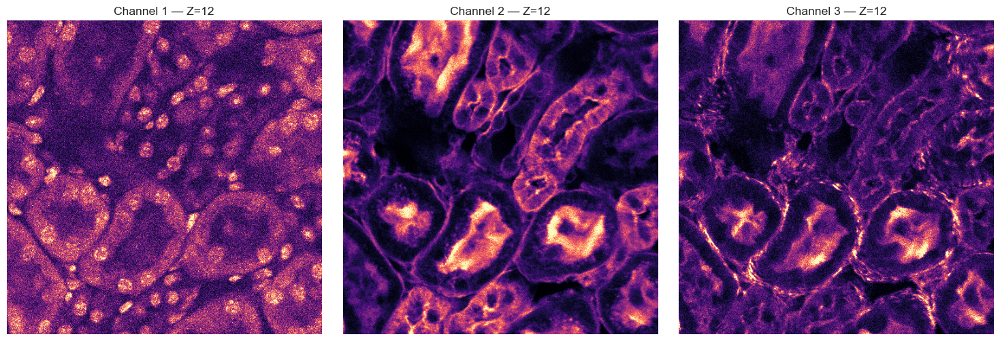

In [3]:
# =============================================================================
# CONFIGURATION — adjust paths and parameters to your dataset
# =============================================================================
CONFIG = {
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels",
    "file_ch1": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif",
    "file_ch2": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif",
    "file_ch3": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif",
    "channel_names": ["Channel 1", "Channel 2", "Channel 3"],
    "z_target": 11,         # Python index → corresponds to Z=12/50
    "cmap": "magma",
}

# Physical calibration (from ImageJ)
DIST_PX         = 109.0046
DIST_UM         = 31.94
PX_SIZE_UM      = DIST_UM / DIST_PX       # ~0.293 µm/px
SCALE_PX_PER_UM = DIST_PX / DIST_UM       # ~3.41 px/µm

# Pipeline parameters
PARAMS = dict(
    nlm_h          = 0.80,   # NLM filter strength (sigma multiplier)
    tophat_r       = 40,     # White Top-Hat footprint radius (px)
    gauss_bg_sigma = 20,     # Gaussian Subtraction sigma for background estimate
    rl_iters       = 15,     # Richardson-Lucy iterations (see Phase 3 note)
    psf_sigma      = 1.5,    # Gaussian PSF sigma (px)
    psf_size       = 51,     # PSF kernel size (px, must be odd)
)

# =============================================================================
# LOAD Z-STACK AND EXTRACT SLICE Z=12 — all 3 channels
# =============================================================================
os.chdir(CONFIG["folder_path"])

raw_channels = []   # list of 2D float slices, normalised [0, 1]

print(f"Extracting slice Z={CONFIG['z_target'] + 1}...")

for fname in [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"File not found: {p.absolute()}")
    stack = io.imread(p)
    sl = stack[CONFIG["z_target"], :, :] if stack.ndim == 3 else stack
    raw_channels.append(img_as_float(sl))

print(f"Channels loaded: {len(raw_channels)} — shape: {raw_channels[0].shape}")

# Working reference: Channel 1
raw = raw_channels[0]

# Quick overview — all 3 channels
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, name in zip(axes, raw_channels, CONFIG["channel_names"]):
    ax.imshow(img, cmap=CONFIG["cmap"], vmax=np.percentile(img, 99.5))
    ax.set_title(f"{name} — Z={CONFIG['z_target'] + 1}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("00_raw_channels.pdf", bbox_inches="tight", facecolor="white")
plt.show()
plt.close("all")

---
## Phase 1 — Noise Removal

Fluorescence microscopy images are dominated by **Poisson noise** (photon shot noise):
noise variance scales with signal intensity and is therefore non-stationary.

> **Note on local filters (Mean, Median, Gaussian):** these assume additive, stationary
> Gaussian noise with constant variance across the image. This assumption is violated for
> Poisson noise — they over-smooth bright regions and under-correct dark ones.
> **They are not suitable for microscopy data** and are therefore omitted.

**Adopted strategy — 2 sub-steps:**
1. **Anscombe Transform**: variance-stabilising transform that converts Poisson(λ) noise
   into approximately unit-variance Gaussian noise, making NLM statistically valid.
2. **Non-Local Means (NLM)**: exploits patch self-similarity across the image to suppress
   noise while preserving fine structures — far superior to local filters.

In [4]:
# =============================================================================
# PHASE 1 — Step A: Anscombe Transform (Variance Stabilisation)
# =============================================================================
# f(x) = 2 * sqrt(x + 3/8)  maps  Poisson(λ)  →  N(0, 1)
# This makes NLM applicable as if the noise were stationary Gaussian.

img_ansc  = 2.0 * np.sqrt(np.maximum(raw, 0) + 3.0 / 8.0)
sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))
print(f"Estimated sigma in Anscombe domain: {sigma_est:.4f}")

Estimated sigma in Anscombe domain: 0.0001


In [5]:
# =============================================================================
# PHASE 1 — Step B: Non-Local Means (NLM)
# =============================================================================
# Key parameters:
#   h              → filter strength (fraction of estimated sigma)
#   patch_size     → patch size in pixels
#   patch_distance → search window radius for similar patches
#   fast_mode=True → efficient approximation (recommended for large images)

img_nlm_ansc = restoration.denoise_nl_means(
    img_ansc,
    h              = PARAMS["nlm_h"] * sigma_est,
    fast_mode      = True,
    patch_size     = 5,
    patch_distance = 6,
)

# Exact unbiased inverse Anscombe transform: x̂ = (f/2)² - 3/8
img_denoised = np.maximum((img_nlm_ansc / 2.0) ** 2 - 3.0 / 8.0, 0)

print("Anscombe + NLM denoising complete.")

Anscombe + NLM denoising complete.


Immagine salvata con successo in: /Users/francesco/Repositories /noise_images/immagini_rel/anascombe.png


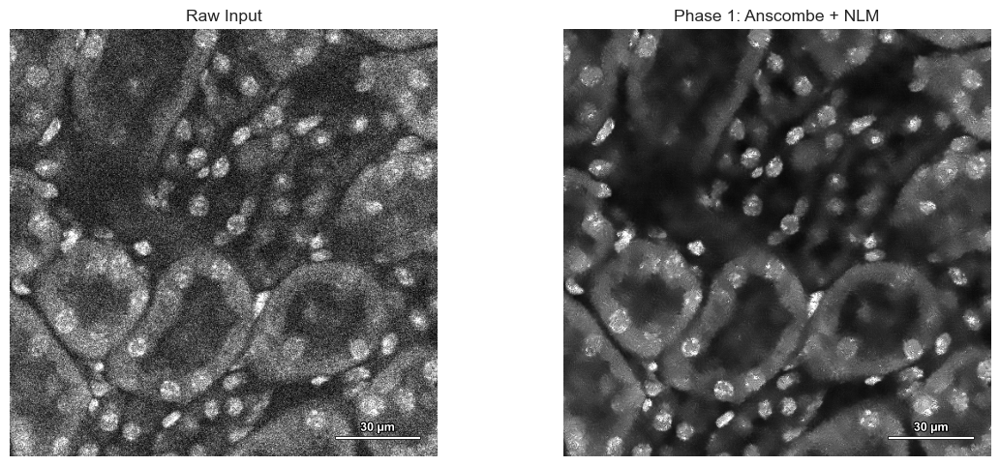

In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# 1. Definiamo la directory di salvataggio
SAVE_DIR = Path('/Users/francesco/Repositories /noise_images/immagini_rel')
SAVE_DIR.mkdir(parents=True, exist_ok=True) # Crea la cartella se non esiste

# Phase 1 visual check: Raw vs Denoised
vmax = np.percentile(raw, 99.5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, img, title in zip(axes,
                           [raw, img_denoised],
                           ["Raw Input", "Phase 1: Anscombe + NLM"]):
    ax.imshow(img, cmap="gray", vmax=vmax)
    ax.set_title(title)
    ax.axis("off")

    # CORREZIONE: Chiamata diretta senza parentesi quadre o cicli "for" interni
    add_scalebar(ax, px_per_um=SCALE_PX_PER_UM, bar_um=30)

plt.tight_layout()

# 2. SALVATAGGIO: Deve sempre avvenire PRIMA di plt.show()
file_path = SAVE_DIR / "anascombe.png"
plt.savefig(file_path, bbox_inches="tight", facecolor="white", dpi=300)
print(f"Immagine salvata con successo in: {file_path}")

# 3. Visualizzazione e chiusura
plt.show()
plt.close("all")

---
## Phase 2 — Background Removal

Fluorescence microscopy is affected by a non-uniform background component
(autofluorescence, out-of-focus scatter, illumination gradient). It must be estimated
and subtracted **before** deconvolution, otherwise Richardson-Lucy will amplify it.

Three equivalent strategies are implemented — choose the one best suited to your dataset:
- **White Top-Hat** *(default)*: morphological, robust, controlled by footprint radius.
- **Gaussian Subtraction**: background estimated as a heavily blurred version (large sigma ~20 px).
- **Rolling Ball**: classic ImageJ-style algorithm, effective for slowly varying backgrounds.

In [7]:
# =============================================================================
# PHASE 2 — Option A: White Top-Hat (recommended default)
# =============================================================================
# Returns: image - morphological_erosion(image)
# The footprint disk must be larger than the structures of interest
# so the slowly varying background is captured and removed.
footprint     = disk(PARAMS["tophat_r"])
img_bg_tophat = white_tophat(img_denoised, footprint)
print(f"White Top-Hat applied (footprint radius = {PARAMS['tophat_r']} px).")

White Top-Hat applied (footprint radius = 40 px).


In [8]:
# =============================================================================
# PHASE 2 — Option B: Gaussian Subtraction
# =============================================================================
# Background estimated as a strongly blurred image (large sigma).
# sigma=20 is typical for 512 px microscopy; adjust to match structure size.
background_gauss = gaussian_filter(img_denoised, sigma=PARAMS["gauss_bg_sigma"])
img_bg_gauss     = np.maximum(img_denoised - background_gauss, 0)
print(f"Gaussian Subtraction applied (sigma={PARAMS['gauss_bg_sigma']}).")

Gaussian Subtraction applied (sigma=20).


In [9]:
# =============================================================================
# PHASE 2 — Option C: Rolling Ball  (requires skimage >= 0.19)
# =============================================================================
# --- 1. Ensure float + normalization (CRITICAL) ---
img = img_denoised.astype(np.float32)
img = (img - img.min()) / (img.max() - img.min() + 1e-8)

# --- 2. Rolling Ball background estimation ---
radius = 30  # biologically reasonable default (adjust if nuclei size changes)
background_rb = rolling_ball(img, radius=radius)

# --- 3. Background subtraction ---
img_bg_rollingball = img - background_rb
img_bg_rollingball = np.clip(img_bg_rollingball, 0, None)

# --- 4. Normalize for visualization ---
img_bg_rollingball = img_bg_rollingball / (img_bg_rollingball.max() + 1e-8)

Confronto salvato in: /Users/francesco/Repositories /noise_images/immagini_rel/background_comparison.png


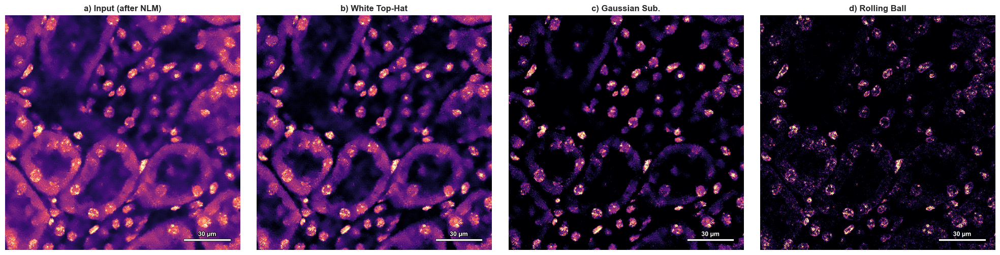

In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# 1. Configurazione Path
SAVE_DIR = Path('/Users/francesco/Repositories /noise_images/immagini_rel')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 2. Visualizzazione Side-by-side (Grayscale per analisi tecnica)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

titles = [
    "a) Input (after NLM)",
    "b) White Top-Hat",
    "c) Gaussian Sub.",
    "d) Rolling Ball",
]
imgs = [img_denoised, img_bg_tophat, img_bg_gauss, img_bg_rollingball]

for ax, img, t in zip(axes, imgs, titles):
    # Usiamo 99.5 percentile per il contrasto e cmap='gray' per il saggio
    vmax = np.percentile(img, 99.5)
    ax.imshow(img, cmap='magma', vmax=vmax)
    ax.set_title(t, fontsize=12, fontweight='bold')
    ax.axis("off")
    
    # Aggiungiamo la barra di scala (30um come nelle precedenti)
    add_scalebar(ax, px_per_um=SCALE_PX_PER_UM, bar_um=30)

plt.tight_layout()

# 3. SALVATAGGIO del confronto (utile per la discussione dei metodi)
comparison_path = SAVE_DIR / "background_comparison.png"
plt.savefig(comparison_path, bbox_inches="tight", facecolor="white", dpi=300)


print(f"Confronto salvato in: {comparison_path}")


plt.show()
plt.close("all")

---
## Phase 3 — Deconvolution (Richardson-Lucy)

Deconvolution inverts the effect of the optical **PSF (Point Spread Function)**,
upgrading from *Pure Denoising* to *Denoised Deconvolution*.

**Richardson-Lucy (R-L)** is an iterative Bayesian algorithm, statistically optimal for
Poisson noise:

$$x^{(k+1)} = x^{(k)} \cdot \left[ h^* \ast \frac{y}{h \ast x^{(k)}} \right]$$

where `h` is the PSF, `y` the observed image, and `*` denotes convolution.

> **⚠️ Iteration count `rl_iters`:**
> R-L is semi-convergent: too few → under-correction (residual blur);
> too many → **noise amplification**, ringing artefacts, and divergence.
> Typical range for microscopy: **10–30 iterations**. Tune empirically.

**PSF model:** a **Gaussian PSF** is used as a practical approximation of the central lobe
of the Airy function. For metric applications (e.g. physical FWHM) it can be replaced
by a Born-Wolf model.

---
## Cell Zoom

Raw vs final output on a cropped ROI centred on a nucleus:
sharpening improvements and background suppression become clearly visible.

[0] Immagine caricata da disco (Slice Z=12).
[0] Input: shape=(512, 512), range=[0.0000, 0.0014]
[1] Denoising Anscombe + NLM...
[2] White Top-Hat  r=40...
[3] Calculating Born & Wolf PSF...
[3] Richardson-Lucy (15 iterations)...
✅ Pipeline complete.
✅ Immagine salvata con successo in:
   /Users/francesco/Repositories /noise_images/immagini_rel/completo.png


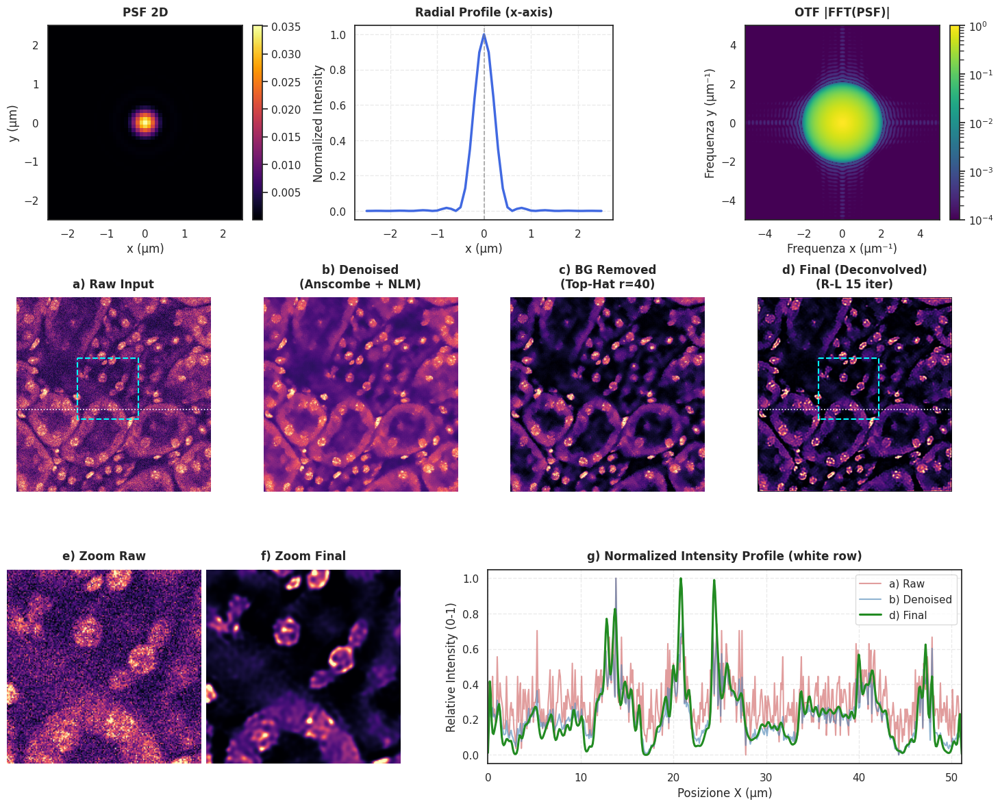

In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from matplotlib.colors import LogNorm
from skimage import img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.exposure import rescale_intensity
from skimage.io import imread
from scipy.special import j0

try:
    from numpy import trapezoid
except ImportError:
    from numpy import trapz as trapezoid

# =============================================================================
# PARAMETERS
# =============================================================================
MICROSCOPE = dict(NA=0.8, wavelength=0.770, ni=1.000, pixel_size=0.100)

PARAMS = dict(
    # Denoising
    nlm_h_factor     = 0.80,
    nlm_patch        = 5,
    nlm_dist         = 6,
    # Background removal
    tophat_radius    = 40,
    # PSF / Deconvolution
    psf_size         = 51,
    psf_n_samples    = 256,
    rl_iters         = 15,
    rl_epsilon       = 1e-6,
    # Visualization
    cmap             = "magma",
    roi              = (160, 320, 160, 320),   # y0, y1, x0, x1
    profile_line     = 295,                    # riga da estrarre
)

# =============================================================================
# UTILITIES
# =============================================================================
def _anscombe(img):
    return 2.0 * np.sqrt(np.maximum(img, 0) + 3.0 / 8.0)

def _inv_anscombe(img):
    return np.maximum((img / 2.0) ** 2 - 3.0 / 8.0, 0)

def _norm_percentile(img, lo=0.1, hi=99.9):
    vmin, vmax = np.percentile(img, lo), np.percentile(img, hi)
    return rescale_intensity(img, in_range=(vmin, vmax), out_range=(0.0, 1.0))

def _scale_for_plot(arr):
    return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)

def make_born_wolf_psf(p: dict, size: int, n_samples: int) -> np.ndarray:
    k   = 2 * np.pi * p["ni"] / p["wavelength"]
    ax  = (np.arange(size) - size // 2) * p["pixel_size"]
    rho = np.linspace(0, 1, n_samples)
    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r         = np.sqrt(x**2 + y**2)
            integrand = j0(k * p["NA"] * r * rho / p["ni"]) * rho
            psf[i, j] = trapezoid(integrand, rho) ** 2
    return psf / psf.sum()

# =============================================================================
# STEP 0 — INPUT
# =============================================================================
IMAGE_PATH = "/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"

if IMAGE_PATH:
    # Carica l'immagine fornita dall'utente (stack 3D)
    stack = imread(IMAGE_PATH)
    # Seleziona lo slice Z=12 (indice 11) e converte in float
    raw = img_as_float(stack[11, :, :])
    print(f"[0] Immagine caricata da disco (Slice Z=12).")
else:
    print("[0] ⚠️ Nessun percorso fornito. Generazione di un'immagine sintetica di test...")
    np.random.seed(42)
    y_grid, x_grid = np.mgrid[0:512, 0:512]
    raw = np.zeros((512, 512))
    # Creiamo finti nuclei/cellule fluorescenti
    for _ in range(60):
        cy, cx = np.random.randint(50, 460, 2)
        r = np.random.uniform(3, 8)
        raw += np.exp(-((x_grid - cx)**2 + (y_grid - cy)**2) / (2 * r**2))
    raw = rescale_intensity(raw, out_range=(0.1, 0.7))
    # Aggiungiamo rumore di Poisson e Gaussiano per simulare uno scatto al microscopio
    raw = np.random.poisson(raw * 50) / 50.0
    raw += np.random.normal(0, 0.05, raw.shape)
    raw = np.clip(raw, 0, 1)

print(f"[0] Input: shape={raw.shape}, range=[{raw.min():.4f}, {raw.max():.4f}]")

# =============================================================================
# STEP 1 — DENOISING  (Anscombe + NLM)
# =============================================================================
print("[1] Denoising Anscombe + NLM...")
img_ansc     = _anscombe(raw)
sigma_est    = float(np.mean(restoration.estimate_sigma(img_ansc)))
img_nlm      = restoration.denoise_nl_means(
    img_ansc,
    h              = PARAMS["nlm_h_factor"] * sigma_est,
    fast_mode      = True,
    patch_size     = PARAMS["nlm_patch"],
    patch_distance = PARAMS["nlm_dist"],
)
img_denoised = np.clip(_inv_anscombe(img_nlm), 0, None)

# =============================================================================
# STEP 2 — BACKGROUND REMOVAL  (White Top-Hat)
# =============================================================================
print(f"[2] White Top-Hat  r={PARAMS['tophat_radius']}...")
img_bg_removed = white_tophat(img_denoised, disk(PARAMS["tophat_radius"]))

# =============================================================================
# STEP 3 — PSF + DECONVOLUTION  (Richardson-Lucy)
# =============================================================================
print("[3] Calculating Born & Wolf PSF...")
psf = make_born_wolf_psf(MICROSCOPE, size=PARAMS["psf_size"], n_samples=PARAMS["psf_n_samples"])

print(f"[3] Richardson-Lucy ({PARAMS['rl_iters']} iterations)...")
img_deconv = restoration.richardson_lucy(
    np.clip(img_bg_removed, 0, None),
    psf,
    num_iter       = PARAMS["rl_iters"],
    filter_epsilon = PARAMS["rl_epsilon"],
)

img_final = _norm_percentile(img_deconv)
print("✅ Pipeline complete.")

# =============================================================================
# UNIFIED VISUALIZATION WITH SEABORN & SUBGRIDSPECS
# =============================================================================
sns.set_theme(style="white", context="notebook", palette="deep")

fig = plt.figure(figsize=(18, 14))

# Creiamo una griglia principale con 3 righe per isolare le spaziature
gs_main = fig.add_gridspec(3, 1, hspace=0.4)

# --- ROW 0: PSF & OTF ---
gs_row0 = gs_main[0].subgridspec(1, 3, wspace=0.35)
ax_psf2d   = fig.add_subplot(gs_row0[0])
ax_psf_rad = fig.add_subplot(gs_row0[1])
ax_otf     = fig.add_subplot(gs_row0[2])

size, center = psf.shape[0], psf.shape[0] // 2
pixel_size = MICROSCOPE["pixel_size"]
ax_um = (np.arange(size) - center) * pixel_size
profile = psf[center, :]
otf = np.abs(np.fft.fftshift(np.fft.fft2(psf)))
otf /= otf.max()

# Plot PSF 2D
im0 = ax_psf2d.imshow(psf, cmap="inferno", origin="lower",
                      extent=[-center * pixel_size, center * pixel_size,
                              -center * pixel_size, center * pixel_size])
ax_psf2d.set_title("PSF 2D", fontsize=12, fontweight="bold", pad=10)
ax_psf2d.set_xlabel("x (µm)"); ax_psf2d.set_ylabel("y (µm)")
ax_psf2d.grid(False)
fig.colorbar(im0, ax=ax_psf2d, fraction=0.046, pad=0.04)

# Plot Radial Profile
ax_psf_rad.plot(ax_um, profile / profile.max(), color="royalblue", lw=2.5)
ax_psf_rad.axvline(0, color="gray", lw=1.2, ls="--", alpha=0.7)
ax_psf_rad.set_title("Radial Profile (x-axis)", fontsize=12, fontweight="bold", pad=10)
ax_psf_rad.set_xlabel("x (µm)"); ax_psf_rad.set_ylabel("Normalized Intensity")
ax_psf_rad.grid(True, alpha=0.4, linestyle="--")

# Calcolo estensione e plot OTF con LogNorm per enfatizzare le alte frequenze
# Creiamo una tela nera più grande (es. 256x256) per avere più risoluzione in frequenza
pad_size = 256
pad_w = (pad_size - psf.shape[0]) // 2
psf_padded = np.pad(psf, pad_width=pad_w, mode='constant')

# Calcoliamo l'OTF sulla matrice ingrandita
otf = np.abs(np.fft.fftshift(np.fft.fft2(psf_padded)))
otf /= otf.max()
freq_max = 1.0 / (2 * pixel_size)
otf_extent = [-freq_max, freq_max, -freq_max, freq_max]

im2 = ax_otf.imshow(otf, cmap="viridis", origin="lower", extent=otf_extent, 
                    norm=LogNorm(vmin=1e-4, vmax=1.0))
ax_otf.set_title("OTF |FFT(PSF)|", fontsize=12, fontweight="bold", pad=10)
ax_otf.set_xlabel("Frequenza x (µm⁻¹)"); ax_otf.set_ylabel("Frequenza y (µm⁻¹)")
ax_otf.grid(False)
fig.colorbar(im2, ax=ax_otf, fraction=0.046, pad=0.04)


# --- ROW 1: PIPELINE STAGES ---
gs_row1 = gs_main[1].subgridspec(1, 4, wspace=0.15)
stages = [
    (raw,            "a) Raw Input"),
    (img_denoised,   "b) Denoised\n(Anscombe + NLM)"),
    (img_bg_removed, f"c) BG Removed\n(Top-Hat r={PARAMS['tophat_radius']})"),
    (img_final,      f"d) Final (Deconvolved)\n(R-L {PARAMS['rl_iters']} iter)"),
]

axes_pipe = [fig.add_subplot(gs_row1[i]) for i in range(4)]
y0, y1, x0, x1 = PARAMS["roi"]
line_y = PARAMS["profile_line"]

for i, (ax, (img, title)) in enumerate(zip(axes_pipe, stages)):
    ax.imshow(img, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(img, 99.5))
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.axis("off")
    
    if i == 0 or i == 3:
        rect = patches.Rectangle((x0, y0), x1 - x0, y1 - y0, 
                                 linewidth=1.5, edgecolor='cyan', 
                                 facecolor='none', linestyle='--')
        ax.add_patch(rect)
        ax.axhline(line_y, color='white', linewidth=1.2, linestyle=':', alpha=1)

# --- ROW 2: ROI ZOOM & INTENSITY PROFILE ---
gs_row2 = gs_main[2].subgridspec(1, 2, width_ratios=[1, 1.2], wspace=0.2)
gs_zooms = gs_row2[0].subgridspec(1, 2, wspace=0.02)

ax_zraw = fig.add_subplot(gs_zooms[0])
ax_zfin = fig.add_subplot(gs_zooms[1])
ax_prof = fig.add_subplot(gs_row2[1])

# e) Zoom Raw
crop_raw = raw[y0:y1, x0:x1]
ax_zraw.imshow(crop_raw, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(crop_raw, 99.5))
ax_zraw.set_title(f"e) Zoom Raw", fontsize=12, fontweight="bold", pad=10)
ax_zraw.axis("off")

# f) Zoom Final
crop_final = img_final[y0:y1, x0:x1]
ax_zfin.imshow(crop_final, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(crop_final, 99.5))
ax_zfin.set_title(f"f) Zoom Final", fontsize=12, fontweight="bold", pad=10)
ax_zfin.axis("off")

# g) Intensity Profile (Asse X convertito in micrometri)
asse_x_um = np.arange(raw.shape[1]) * pixel_size

ax_prof.plot(asse_x_um, _scale_for_plot(raw[line_y, :]),          color="indianred",   alpha=0.6, lw=1.5, label="a) Raw")
ax_prof.plot(asse_x_um, _scale_for_plot(img_denoised[line_y, :]), color="steelblue",  alpha=0.6, lw=1.5, label="b) Denoised")
ax_prof.plot(asse_x_um, _scale_for_plot(img_final[line_y, :]),    color="forestgreen", lw=2.2,            label="d) Final")
ax_prof.set_title(f"g) Normalized Intensity Profile (white row)", fontsize=12, fontweight="bold", pad=10)
ax_prof.set_xlabel("Posizione X (µm)")
ax_prof.set_ylabel("Relative Intensity (0-1)")
ax_prof.legend(frameon=True, facecolor="white", edgecolor="lightgray")
ax_prof.grid(True, alpha=0.4, linestyle="--")
ax_prof.margins(x=0)

sns.reset_orig()

# =============================================================================
# SALVATAGGIO IMMAGINE
# =============================================================================
cartella_salvataggio = "/Users/francesco/Repositories /noise_images/immagini_rel"

# Assicurati che la cartella esista (se non c'è, la crea lui senza darti errore)
os.makedirs(cartella_salvataggio, exist_ok=True)

# Crea il percorso completo unendo la cartella e il nome che vuoi dare al file
salvataggio_path = os.path.join(cartella_salvataggio, "completo.png")

# Salva l'immagine in alta qualità
plt.savefig(salvataggio_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"✅ Immagine salvata con successo in:\n   {salvataggio_path}")

# Mostra l'immagine a schermo
plt.show()

# Output variable for subsequent cells
image_final_hr = img_final

---
## Intensity Profiles

Horizontal profile extracted through a nucleus highlights:
- reduction of high-frequency oscillations (noise) after denoising
- recovery of intensity peaks after deconvolution

Profiles are **individually normalised [0, 1]** so shapes and widths are comparable
regardless of each step's absolute intensity.

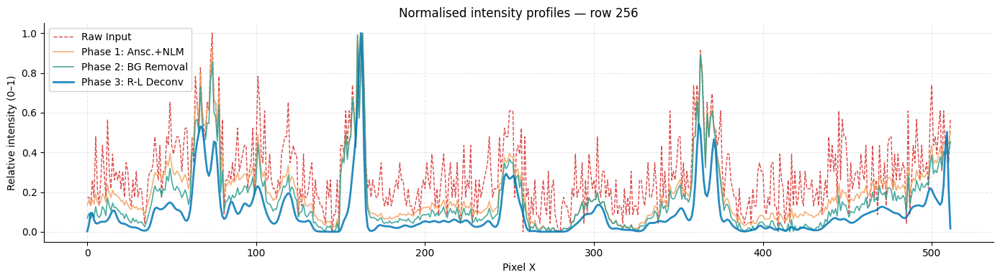

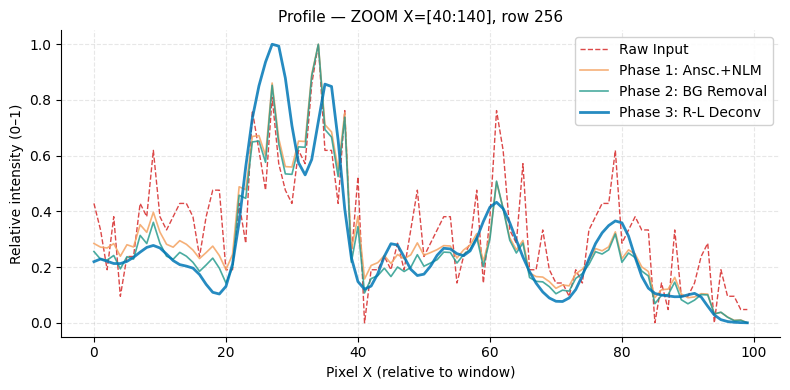

In [12]:
# =============================================================================
# INTENSITY PROFILES — normalised 0-1 for visual comparison
# =============================================================================
# Sampling row: through a nucleus (adjust ROW_IDX if needed)
ROW_IDX = raw.shape[0] // 2

def scale01(arr: np.ndarray) -> np.ndarray:
    """Min-max normalisation [0, 1] for shape comparison (not absolute intensity)."""
    mn, mx = arr.min(), arr.max()
    return (arr - mn) / (mx - mn + 1e-9)


profile_stages = [
    (raw,            "Raw Input",           "#D62828", 1.0, "--"),
    (img_denoised,   "Phase 1: Ansc.+NLM",  "#F4A261", 1.2, "-"),
    (img_bg_removed, "Phase 2: BG Removal", "#2A9D8F", 1.2, "-"),
    (img_deconv,     "Phase 3: R-L Deconv", "#0077B6", 2.0, "-"),
]

# Full-width profile
fig, ax = plt.subplots(figsize=(14, 4))
for img, label, color, lw, ls in profile_stages:
    ax.plot(scale01(img[ROW_IDX, :]), label=label,
            color=color, linewidth=lw, linestyle=ls, alpha=0.85)
ax.set_title(f"Normalised intensity profiles — row {ROW_IDX}", fontsize=12)
ax.set_xlabel("Pixel X")
ax.set_ylabel("Relative intensity (0–1)")
ax.legend(fontsize=10, framealpha=0.9)
ax.grid(alpha=0.3, linestyle="--")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
plt.close("all")

# Zoomed profile — nucleus region
X_ZOOM_START, X_ZOOM_END = 40, 140   # adjust to the target nucleus

fig, ax = plt.subplots(figsize=(8, 4))
for img, label, color, lw, ls in profile_stages:
    ax.plot(scale01(img[ROW_IDX, X_ZOOM_START:X_ZOOM_END]), label=label,
            color=color, linewidth=lw, linestyle=ls, alpha=0.85)
ax.set_title(f"Profile — ZOOM X=[{X_ZOOM_START}:{X_ZOOM_END}], row {ROW_IDX}", fontsize=11)
ax.set_xlabel("Pixel X (relative to window)")
ax.set_ylabel("Relative intensity (0–1)")
ax.legend(fontsize=10, framealpha=0.9)
ax.grid(alpha=0.3, linestyle="--")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
plt.close("all")

---
## Quantitative Evaluation — SNR, CNR, FWHM

Numerical comparison across pipeline stages on 3 physical metrics:
- **SNR** = μ_signal / σ_background
- **CNR** = |μ_signal − μ_background| / σ_background
- **FWHM** (µm): half-maximum width of the intensity profile on a selected nucleus

Signal (green) and background (white) ROIs are drawn directly on the images.

✅ Immagine salvata con successo in:
   /Users/francesco/Repositories /noise_images/immagini_rel/SNR.png


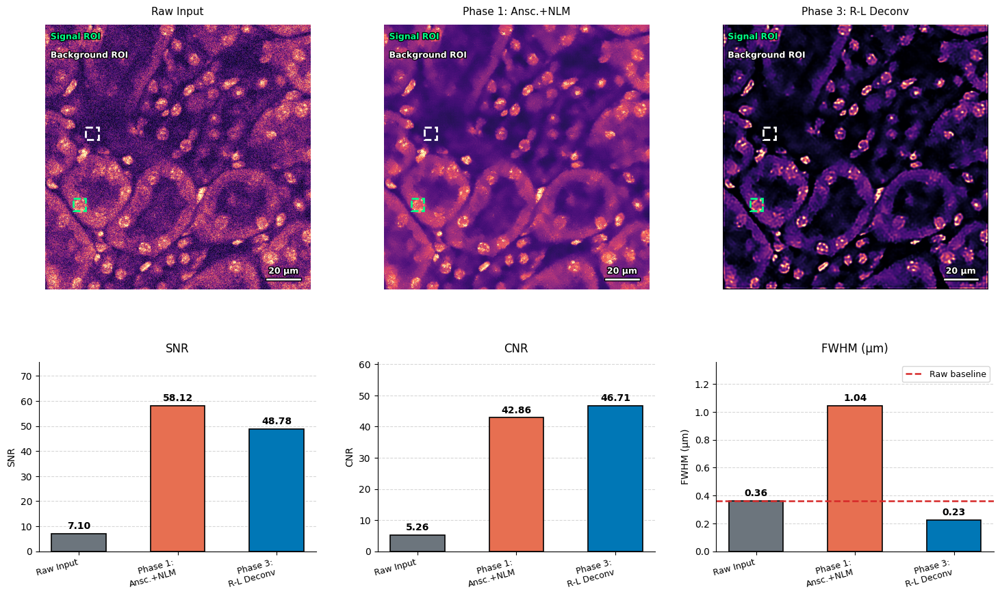

Figure saved to benchmark_pipeline.pdf


In [13]:
# =============================================================================
# SCIENTIFIC FIGURE — images with ROI + seaborn bar charts
# =============================================================================

# --- Ricostruisce risultati se cell 17 non è stata eseguita ---
try:
    risultati
except NameError:
    risultati = {
        "Raw Input"           : raw,
        "Phase 1: Ansc.+NLM"  : img_denoised,
        "Phase 2: BG Removal" : img_bg_removed,
        "Phase 3: R-L Deconv" : img_deconv,
    }
    vmax_shared = np.percentile(raw, 99.5)

labels = list(risultati.keys())

# --- Ricomputa metrics se cell 23 non è stata eseguita ---
Y_SIG, X_SIG = 348, 65
Y_BG,  X_BG  = 210, 90
HALF_ROI     = 12

try:
    metrics
except NameError:
    from scipy.interpolate import UnivariateSpline

    def calculate_local_fwhm(img, y, x, window=40):
        start   = max(0, x - window)
        end     = min(img.shape[1], x + window)
        profile = img[y, start:end] - img[y, start:end].min()
        p_max   = profile.max()
        if p_max == 0:
            return np.nan
        spline = UnivariateSpline(np.arange(len(profile)), profile - p_max / 2.0, s=0)
        roots  = spline.roots()
        if len(roots) >= 2:
            idx = np.argsort(np.abs(roots - window))
            return float(np.abs(roots[idx[1]] - roots[idx[0]]))
        return np.nan

    metrics = {"SNR": [], "CNR": [], "FWHM (µm)": []}
    for title, img in risultati.items():
        mu_s  = img[Y_SIG-HALF_ROI:Y_SIG+HALF_ROI, X_SIG-HALF_ROI:X_SIG+HALF_ROI].mean()
        mu_b  = img[Y_BG -HALF_ROI:Y_BG +HALF_ROI, X_BG -HALF_ROI:X_BG +HALF_ROI].mean()
        std_b = img[Y_BG -HALF_ROI:Y_BG +HALF_ROI, X_BG -HALF_ROI:X_BG +HALF_ROI].std() + 1e-9
        metrics["SNR"].append(mu_s / std_b)
        metrics["CNR"].append(np.abs(mu_s - mu_b) / std_b)
        metrics["FWHM (µm)"].append(calculate_local_fwhm(img, Y_SIG, X_SIG) * PX_SIZE_UM)

# =============================================================================
COLORS    = ["#6C757D", "#E76F51", "#2A9D8F", "#0077B6"]
SHOW_KEYS = ["Raw Input", "Phase 1: Ansc.+NLM", "Phase 3: R-L Deconv"]
show_imgs = [(k, risultati[k]) for k in SHOW_KEYS]
show_idx  = [labels.index(k) for k in SHOW_KEYS]

_psf_label = (f"σ={PARAMS['psf_sigma']} px"      if "psf_sigma"    in PARAMS else
              f"{PARAMS['psf_n_samples']} samples" if "psf_n_samples" in PARAMS else "—")

fig = plt.figure(figsize=(18, 10))
gs  = fig.add_gridspec(2, 3, height_ratios=[1.4, 1], hspace=0.32, wspace=0.22)

for col, (title, img) in enumerate(show_imgs):
    ax = fig.add_subplot(gs[0, col])
    ax.imshow(img, cmap=CONFIG["cmap"], vmin=0, vmax=vmax_shared)
    ax.set_title(title, fontsize=11, pad=10)
    ax.axis("off")

    ax.add_patch(patches.Rectangle(
        (X_SIG - HALF_ROI, Y_SIG - HALF_ROI), 2 * HALF_ROI, 2 * HALF_ROI,
        linewidth=2, edgecolor="#00FF88", linestyle="--", fill=False))
    ax.add_patch(patches.Rectangle(
        (X_BG - HALF_ROI, Y_BG - HALF_ROI), 2 * HALF_ROI, 2 * HALF_ROI,
        linewidth=2, edgecolor="white", linestyle="--", fill=False))

    stroke = [pe.withStroke(linewidth=1.8, foreground="black")]
    ax.text(0.02, 0.97, "Signal ROI",     transform=ax.transAxes,
            fontsize=9, color="#00FF88", va="top", weight="bold", path_effects=stroke)
    ax.text(0.02, 0.90, "Background ROI", transform=ax.transAxes,
            fontsize=9, color="white",    va="top", weight="bold", path_effects=stroke)

    sb_px  = 20 * SCALE_PX_PER_UM
    mg     = 18
    ih, iw = img.shape[:2]
    ax.add_patch(patches.Rectangle(
        (iw - mg - sb_px, ih - mg - 5), sb_px, 5,
        linewidth=1, edgecolor="black", facecolor="white", zorder=3))
    ax.text(iw - mg - sb_px / 2, ih - mg - 9, "20 µm",
            color="white", fontsize=9, ha="center", va="bottom", weight="bold",
            path_effects=[pe.withStroke(linewidth=2, foreground="black")], zorder=4)

show_colors = [COLORS[i] for i in show_idx]
x_pos       = range(len(SHOW_KEYS))
x_labels    = [k.replace(": ", ":\n") for k in SHOW_KEYS]

for col, (m_name, m_vals_all) in enumerate(metrics.items()):
    m_vals = [m_vals_all[i] for i in show_idx]
    ax_bar = fig.add_subplot(gs[1, col])

    ax_bar.bar(x_pos, m_vals, color=show_colors,
               edgecolor="black", linewidth=1.2, width=0.55)

    valid = [v for v in m_vals if not np.isnan(v)]
    if valid:
        ax_bar.set_ylim(0, max(valid) * 1.30)
    ax_bar.yaxis.grid(True, linestyle="--", alpha=0.5)
    ax_bar.set_axisbelow(True)
    ax_bar.set_title(m_name, pad=10)
    ax_bar.set_xlabel("")
    ax_bar.set_ylabel(m_name)
    ax_bar.set_xticks(list(x_pos))
    ax_bar.set_xticklabels(x_labels, fontsize=9, rotation=15, ha="right")

    for j, val in enumerate(m_vals):
        if not np.isnan(val):
            ax_bar.text(j, val + 0.015 * ax_bar.get_ylim()[1], f"{val:.2f}",
                        ha="center", va="bottom", fontsize=10, fontweight="bold")

    if "FWHM" in m_name and not np.isnan(m_vals[0]):
        ax_bar.axhline(m_vals[0], color="#D62828", linestyle="--",
                       linewidth=1.8, label="Raw baseline")
        ax_bar.legend(fontsize=9, frameon=True)

    sns.despine(ax=ax_bar)

cartella_salvataggio = "/Users/francesco/Repositories /noise_images/immagini_rel"

# Assicurati che la cartella esista (se non c'è, la crea lui senza darti errore)
os.makedirs(cartella_salvataggio, exist_ok=True)

# Crea il percorso completo unendo la cartella e il nome che vuoi dare al file
salvataggio_path = os.path.join(cartella_salvataggio, "SNR.png")

# Salva l'immagine in alta qualità
plt.savefig(salvataggio_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"✅ Immagine salvata con successo in:\n   {salvataggio_path}")

plt.show()
plt.close("all")
print("Figure saved to benchmark_pipeline.pdf")

---
## RGB Multi-Channel Composition

All 3 channels are processed through the full pipeline and merged into a false-colour RGB:

| Physical channel | RGB colour |
|---|---|
| Channel 1 | Blue |
| Channel 2 | Green |
| Channel 3 | Red |

**Correct comparison:** NLM is an internal pipeline step, not a final output.
The meaningful comparison is between:
- **Raw**: unprocessed 3-channel composite
- **Pure Denoising**: output after Phase 1 + Phase 2 (Anscombe→NLM→BG Removal), **no** deconvolution
- **Denoised Deconvolution**: full pipeline output including Richardson-Lucy (Phase 1+2+3)
- **Hybrid**: per-channel mix (useful when channels have very different SNR)

In [14]:
import numpy as np
psf_sigma = 1.5  # deviazione standard in pixel (regola la sfocatura)
psf_size  = 51   # dimensione del kernel (deve essere dispari per avere un centro esatto)

PARAMS = dict(
    nlm_h          = 0.80,   # NLM filter strength (sigma multiplier)
    tophat_r       = 40,     # White Top-Hat footprint radius (px)
    gauss_bg_sigma = 20,     # Gaussian Subtraction sigma for background estimate
    rl_iters       = 15,     # Richardson-Lucy iterations (see Phase 3 note)
    psf_sigma      = 1.5,    # Gaussian PSF sigma (px)
    psf_size       = 51,     # PSF kernel size (px, must be odd)
)

def make_gaussian_psf(size, sigma):
    """
    Crea una Point Spread Function (PSF) Gaussiana 2D.
    
    Parametri:
    - size: int, la dimensione del kernel (es. 51 per un kernel 51x51). Dovrebbe essere dispari.
    - sigma: float, la deviazione standard della gaussiana (il grado di sfocatura).
    
    Ritorna:
    - psf: array numpy 2D normalizzato (in modo che la somma sia 1).
    """
    center = size // 2
    x = np.arange(0, size)
    y = np.arange(0, size)
    x, y = np.meshgrid(x, y)
    
    # Calcola la Gaussiana 2D
    psf = np.exp(-((x - center)**2 + (y - center)**2) / (2.0 * sigma**2))
    
    # Normalizza in modo che l'energia totale sia 1
    psf = psf / np.sum(psf)
    
    return psf
# =============================================================================
# FULL PIPELINE ON ALL 3 CHANNELS
# Returns per channel: raw, pure_denoised (Ph1+2), deconv (Ph1+2+3)
# =============================================================================

def run_pipeline(img_raw: np.ndarray, params: dict, psf: np.ndarray) -> dict:
    """Run the full pipeline on a single 2D channel.

    Returns
    -------
    dict with keys:
        'raw'           → input image (float)
        'pure_denoised' → after Phase 1 (Anscombe+NLM) + Phase 2 (BG Removal)
        'deconv'        → after Phase 3 (Richardson-Lucy)
    """
    # Phase 1: Anscombe + NLM
    ansc      = 2.0 * np.sqrt(np.maximum(img_raw, 0) + 3.0 / 8.0)
    sigma_e   = float(np.mean(restoration.estimate_sigma(ansc)))
    nlm       = restoration.denoise_nl_means(
        ansc, h=params["nlm_h"] * sigma_e,
        fast_mode=True, patch_size=5, patch_distance=6)
    denoised  = np.maximum((nlm / 2.0) ** 2 - 3.0 / 8.0, 0)

    # Phase 2: White Top-Hat background removal
    pure_den  = white_tophat(denoised, disk(params["tophat_r"]))

    # Phase 3: Richardson-Lucy
    deconv    = restoration.richardson_lucy(
        np.clip(pure_den, 0, None), psf, num_iter=params["rl_iters"])

    return {"raw": img_raw, "pure_denoised": pure_den, "deconv": deconv}


psf_rgb = make_gaussian_psf(size=PARAMS["psf_size"], sigma=PARAMS["psf_sigma"])

print("Running pipeline on 3 channels...")
channel_results = []
for i, (ch_raw, name) in enumerate(zip(raw_channels, CONFIG["channel_names"])):
    print(f"  [{i+1}/3] {name}...", end=" ")
    channel_results.append(run_pipeline(ch_raw, PARAMS, psf_rgb))
    print("done")

print("Multi-channel pipeline complete.")

Running pipeline on 3 channels...
  [1/3] Channel 1... done
  [2/3] Channel 2... done
  [3/3] Channel 3... done
Multi-channel pipeline complete.


In [15]:
# =============================================================================
# RGB COMPOSITION
# Mapping: Ch1→Blue, Ch2→Green, Ch3→Red  (np.dstack expects order R, G, B)
# =============================================================================

def normalize_for_rgb(img: np.ndarray, pmin: float = 0.1, pmax: float = 99.9) -> np.ndarray:
    """Percentile normalisation to [0, 1] — robust to hot pixels."""
    vmin, vmax_r = np.percentile(img, (pmin, pmax))
    return rescale_intensity(img, in_range=(vmin, vmax_r), out_range=(0.0, 1.0))


def make_rgb(ch_list: list, key: str) -> np.ndarray:
    """Compose a false-colour RGB from 3 greyscale channels.
    ch_list[0]=Ch1→Blue, ch_list[1]=Ch2→Green, ch_list[2]=Ch3→Red
    """
    R = normalize_for_rgb(ch_list[2][key])
    G = normalize_for_rgb(ch_list[1][key])
    B = normalize_for_rgb(ch_list[0][key])
    return np.dstack((R, G, B))


rgb_raw           = make_rgb(channel_results, "raw")
rgb_pure_denoised = make_rgb(channel_results, "pure_denoised")
rgb_deconv        = make_rgb(channel_results, "deconv")

# Hybrid: Ch1 (weakest signal) → pure denoised only; Ch2, Ch3 → full deconv
rgb_hybrid = np.dstack((
    normalize_for_rgb(channel_results[2]["pure_denoised"]),   # Ch3 → R
    normalize_for_rgb(channel_results[1]["pure_denoised"]),   # Ch2 → G
    normalize_for_rgb(channel_results[0]["deconv"]),          # Ch1 → B
))

print("RGB composites generated.")

RGB composites generated.


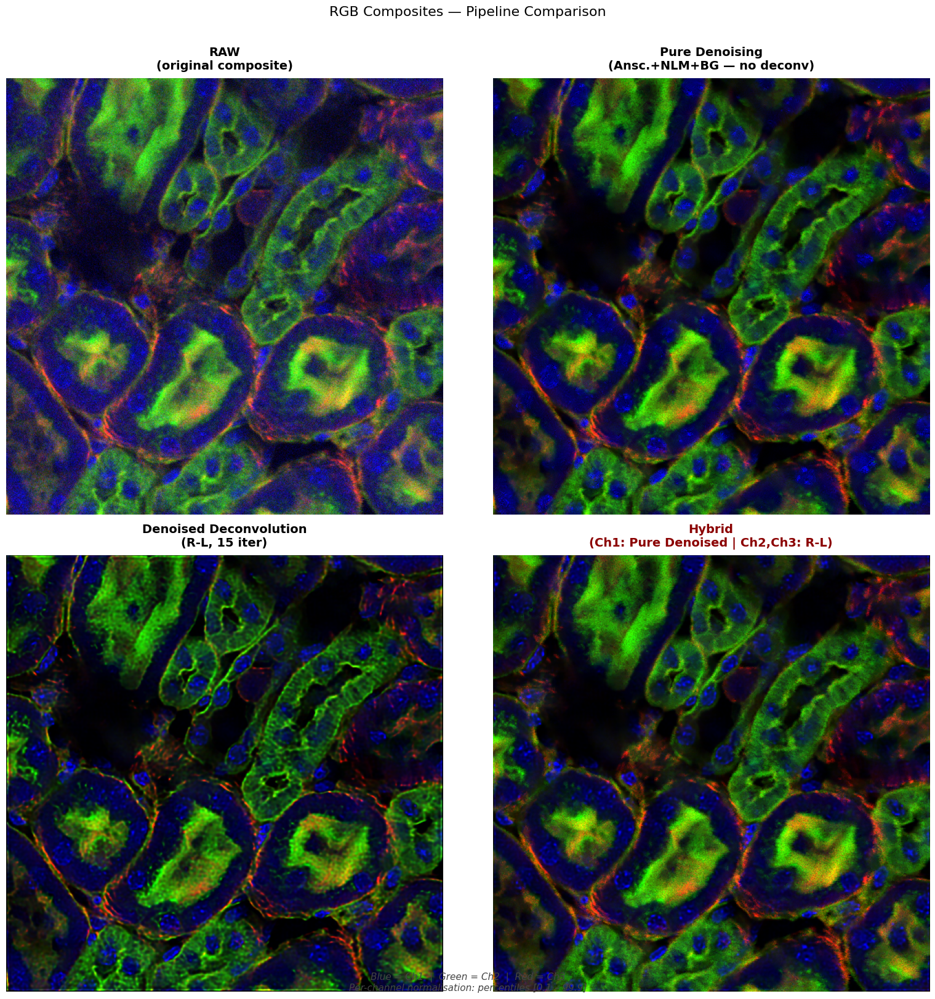

RGB grid saved to rgb_composites.pdf


In [16]:
# =============================================================================
# 2×2 GRID — Raw | Pure Denoised | R-L Deconv | Hybrid
# =============================================================================
composites = [
    (rgb_raw,           "RAW\n(original composite)",                      None),
    (rgb_pure_denoised, "Pure Denoising\n(Ansc.+NLM+BG — no deconv)",     None),
    (rgb_deconv,        f"Denoised Deconvolution\n(R-L, {PARAMS['rl_iters']} iter)", None),
    (rgb_hybrid,        "Hybrid\n(Ch1: Pure Denoised | Ch2,Ch3: R-L)",    "darkred"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, (img, title, tc) in zip(axes.flat, composites):
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(title, fontsize=14, fontweight="bold",
                 color=tc if tc else "black", pad=10)
    ax.axis("off")

legend_text = ("Blue = Ch1  |  Green = Ch2  |  Red = Ch3\n"
               "Per-channel normalisation: percentiles [0.1 – 99.9]")
fig.text(0.5, 0.01, legend_text, ha="center", fontsize=11,
         color="#444444", style="italic")

plt.suptitle("RGB Composites — Pipeline Comparison", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig("rgb_composites.pdf", bbox_inches="tight", facecolor="white")
plt.show()
plt.close("all")
print("RGB grid saved to rgb_composites.pdf")

Calcolo delle iterazioni in corso...


/var/folders/gj/gl2kb7qs563ckkg3vvvr7dvh0000gn/T/ipykernel_61047/1306746233.py:69: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0.1)


Figura finale salvata con successo in: /Users/francesco/Repositories /noise_images/IMM/RL_ITERAZIONI.png


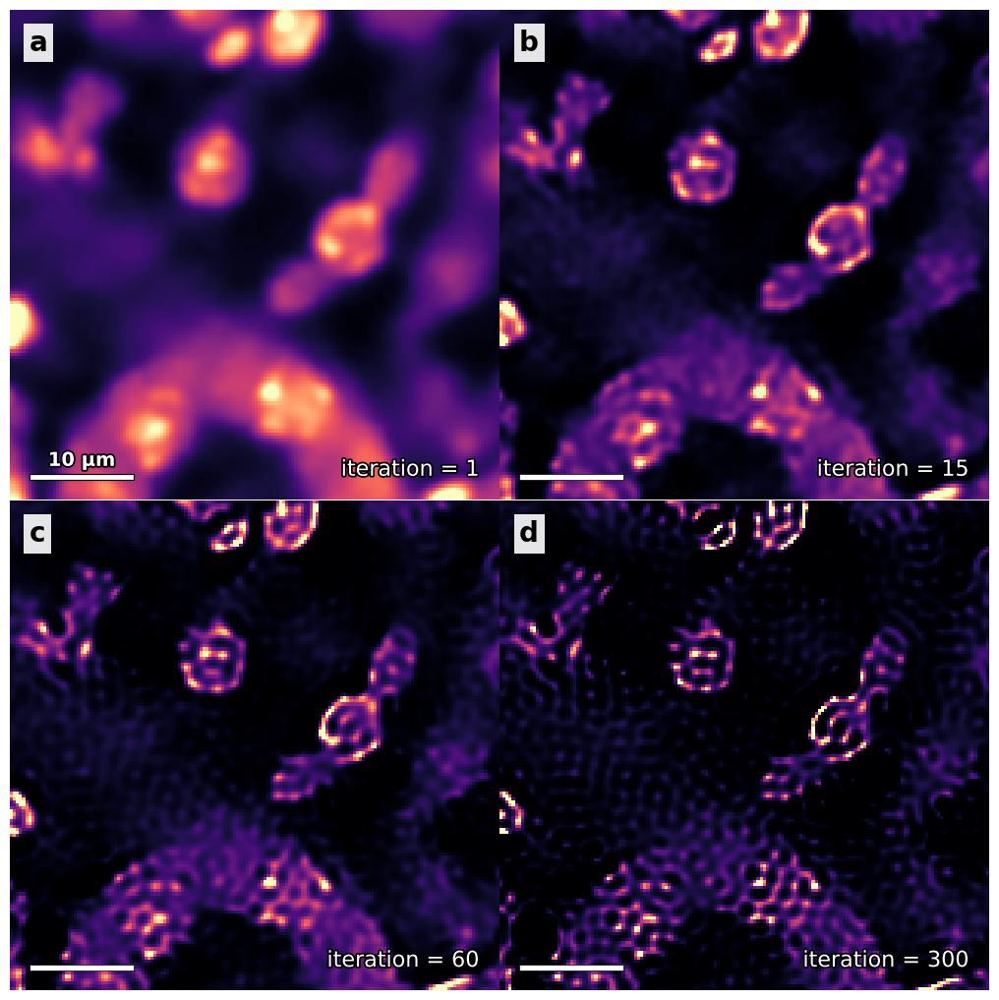

In [17]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
from pathlib import Path
from skimage import restoration

# =============================================================================
# 1. CALCOLO DELLA DECONVOLUZIONE
# =============================================================================
print("Calcolo delle iterazioni in corso...")

target_iters = [1, 15, 60, 300]
grid_data = []
image_clipped = np.clip(img_bg_removed, 0, None)

for it in target_iters:
    img_deconv = restoration.richardson_lucy(
        image    = image_clipped,
        psf      = psf,
        num_iter = it,
    )
    grid_data.append((img_deconv, f"iteration = {it}"))

# =============================================================================
# 2. CONFIGURAZIONE GRIGLIA E ROI
# =============================================================================
ZOOM_Y0, ZOOM_Y1 = 160, 320
ZOOM_X0, ZOOM_X1 = 160, 320
LETTERS = ['a', 'b', 'c', 'd']

SAVE_DIR = Path('/Users/francesco/Repositories /noise_images/IMM')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(10, 10), layout="constrained")

# =============================================================================
# 3. PLOT CON BARRA DI SCALA OTTIMIZZATA
# =============================================================================
for ax, (img_full, label), letter in zip(axes.flatten(), grid_data, LETTERS):
    
    # Estrazione ROI
    roi = img_full[ZOOM_Y0:ZOOM_Y1, ZOOM_X0:ZOOM_X1]
    
    # Visualizzazione
    vmax = np.percentile(roi, 99.5)
    ax.imshow(roi, cmap=CONFIG["cmap"], vmin=0, vmax=vmax)
    ax.axis("off")
    
    # Lettera del pannello
    ax.text(0.04, 0.96, letter, transform=ax.transAxes,
            fontsize=20, fontweight='bold', va='top', ha='left',
            color='black', bbox=dict(facecolor='white', edgecolor='none', pad=4, alpha=0.9))
    
    # Testo iterazione
    ax.text(0.96, 0.04, label, transform=ax.transAxes,
            fontsize=16, va='bottom', ha='right', color='white',
            path_effects=[pe.withStroke(linewidth=2.5, foreground="black")])
    
    # BARRA DI SCALA: Testo solo sulla 'a', solo barra sulle altre
    if letter == 'a':
        add_scalebar(ax, px_per_um=SCALE_PX_PER_UM, bar_um=10, position="bl", box_alpha=0, fontsize=14)
    else:
        # label="" nasconde il numero ma mantiene la barra bianca lunga uguale
        add_scalebar(ax, px_per_um=SCALE_PX_PER_UM, bar_um=10, position="bl", box_alpha=0, label="")

# =============================================================================
# 4. SALVATAGGIO
# =============================================================================
plt.tight_layout(pad=0.1)

file_path_2x2 = SAVE_DIR / "RL_ITERAZIONI.png"
plt.savefig(file_path_2x2, bbox_inches="tight", facecolor="white", dpi=300)

# Poi, prima del salvataggio, puoi affinare:
fig.set_constrained_layout_pads(w_pad=0, h_pad=0, hspace=-0.01, wspace=-0.01)
print(f"Figura finale salvata con successo in: {file_path_2x2}")
plt.show()
plt.close("all")

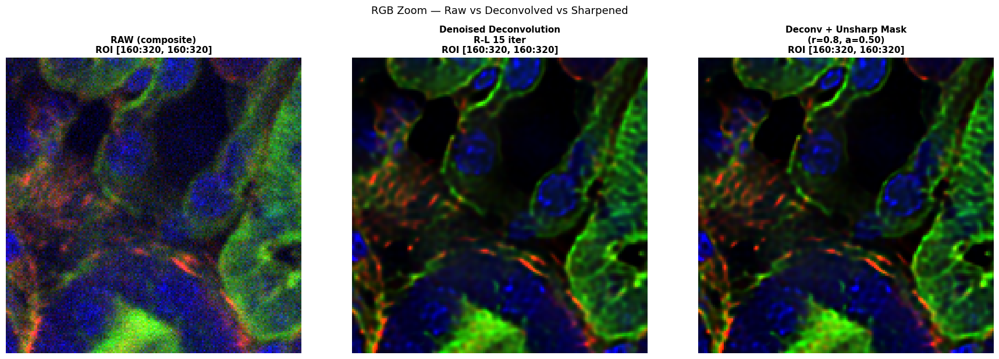

In [18]:
from skimage.filters import gaussian, unsharp_mask

# =============================================================================
# RGB ZOOM — Raw vs Denoised Deconvolution vs Sharpened
# =============================================================================
ZOOM_Y0, ZOOM_Y1 = 160, 320
ZOOM_X0, ZOOM_X1 = 160, 320

# Sharpening DOPO normalize_for_rgb — opera su valori [0,1] dove
# l'effetto è effettivo e non viene annullato dallo stretch successivo
def sharpen_rgb(rgb_img: np.ndarray, radius: float = 0.8, amount: float = 9.95) -> np.ndarray:
    """Apply unsharp mask independently on each RGB channel (already in [0,1])."""
    out = np.stack([
        unsharp_mask(rgb_img[:, :, c], radius=radius, amount=amount)
        for c in range(3)
    ], axis=-1)
    return np.clip(out, 0, 1)


# Costruisci prima l'RGB normalizzato, poi sharpenizza
rgb_sharpened = sharpen_rgb(rgb_deconv, radius=0.8, amount=0.5)

zoom_triplet = [
    (rgb_raw,       "RAW (composite)"),
    (rgb_deconv,    f"Denoised Deconvolution\nR-L {PARAMS['rl_iters']} iter"),
    (rgb_sharpened, "Deconv + Unsharp Mask\n(r=0.8, a=0.50)"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (img, title) in zip(axes, zoom_triplet):
    roi = np.clip(img[ZOOM_Y0:ZOOM_Y1, ZOOM_X0:ZOOM_X1], 0, 1)
    ax.imshow(roi)
    ax.set_title(f"{title}\nROI [{ZOOM_Y0}:{ZOOM_Y1}, {ZOOM_X0}:{ZOOM_X1}]",
                 fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("RGB Zoom — Raw vs Deconvolved vs Sharpened", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
plt.close("all")

Running microscopy-friendly EDSR x4...
EDSR unavailable (module 'cv2' has no attribute 'dnn_superres')


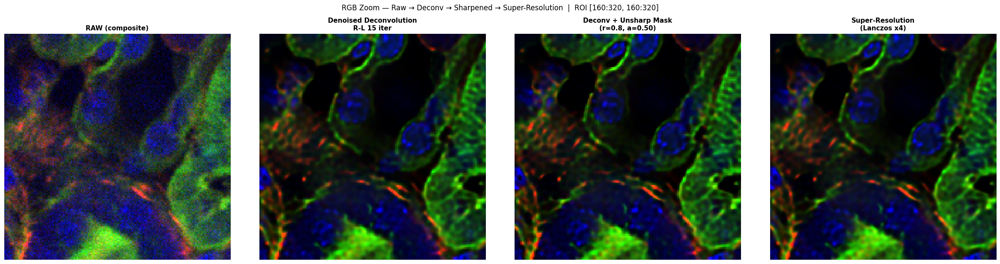

Saved to zoom_superresolution_stabilized.pdf


In [19]:
# =============================================================================
# RGB ZOOM — Raw | Denoised Deconv | Sharpened | Super-Resolution (EDSR x4)
# Improved scientific / microscopy-friendly EDSR pipeline
# =============================================================================
#
# CHANGES vs original:
#   ✓ EDSR applied on deconvolved image (NOT sharpened)
#   ✓ Histogram matching after EDSR
#   ✓ Mean/std intensity preservation
#   ✓ Gentle blend with Lanczos baseline
#   ✓ Reduced saturation / brightness drift
#   ✓ More stable microscopy appearance
#
# =============================================================================

import cv2
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from skimage.exposure import match_histograms

ZOOM_Y0, ZOOM_Y1 = 160, 320
ZOOM_X0, ZOOM_X1 = 160, 320
UPSCALE_FACTOR   = 4

# ── Extract and normalise ROIs ────────────────────────────────────────────────
roi_raw  = np.clip(rgb_raw      [ZOOM_Y0:ZOOM_Y1, ZOOM_X0:ZOOM_X1], 0, 1)
roi_dec  = np.clip(rgb_deconv   [ZOOM_Y0:ZOOM_Y1, ZOOM_X0:ZOOM_X1], 0, 1)
roi_shar = np.clip(rgb_sharpened[ZOOM_Y0:ZOOM_Y1, ZOOM_X0:ZOOM_X1], 0, 1)

# =============================================================================
# Helper conversions
# =============================================================================
def to_bgr_u8(img_rgb_01):
    return cv2.cvtColor(
        (np.clip(img_rgb_01, 0, 1) * 255).astype(np.uint8),
        cv2.COLOR_RGB2BGR
    )

def to_rgb_01(img_bgr_u8):
    return (
        cv2.cvtColor(img_bgr_u8, cv2.COLOR_BGR2RGB)
        .astype(np.float32) / 255.0
    )

# =============================================================================
# EDSR UPSAMPLING
# =============================================================================
def edsr_upsample(roi_rgb_01, scale=4):

    MODEL_PATH = Path("/tmp/EDSR_x4.pb")
    MODEL_URL  = (
        "https://github.com/Saafke/EDSR_Tensorflow/"
        "raw/master/models/EDSR_x4.pb"
    )

    if not MODEL_PATH.exists():
        print(f"Downloading EDSR x{scale} model (~150 MB)...",
              end=" ", flush=True)
        urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)
        print("done.")

    sr = cv2.dnn_superres.DnnSuperResImpl_create()
    sr.readModel(str(MODEL_PATH))
    sr.setModel("edsr", scale)

    out_bgr = sr.upsample(to_bgr_u8(roi_rgb_01))

    return to_rgb_01(out_bgr)

# =============================================================================
# Classical upscale baseline (used for blending stabilization)
# =============================================================================
def lanczos_upscale(img_rgb_01, scale=4):

    h, w = img_rgb_01.shape[:2]

    out = cv2.resize(
        img_rgb_01,
        (w * scale, h * scale),
        interpolation=cv2.INTER_LANCZOS4
    )

    return np.clip(out, 0, 1)

# =============================================================================
# Microscopy-friendly EDSR postprocessing
# =============================================================================
def stabilize_sr(sr_img, ref_img, scale=4,
                 blend_alpha=0.82,
                 preserve_statistics=True,
                 histogram_match=True):

    # -------------------------------------------------------------------------
    # Reference upscale (photometrically stable)
    # -------------------------------------------------------------------------
    ref_up = lanczos_upscale(ref_img, scale=scale)

    # -------------------------------------------------------------------------
    # Histogram matching
    # -------------------------------------------------------------------------
    if histogram_match:
        sr_img = match_histograms(
            sr_img,
            ref_up,
            channel_axis=-1
        )

    # -------------------------------------------------------------------------
    # Preserve global mean/std
    # -------------------------------------------------------------------------
    if preserve_statistics:

        sr_mean = sr_img.mean(axis=(0, 1), keepdims=True)
        sr_std  = sr_img.std(axis=(0, 1), keepdims=True) + 1e-8

        ref_mean = ref_up.mean(axis=(0, 1), keepdims=True)
        ref_std  = ref_up.std(axis=(0, 1), keepdims=True)

        sr_img = (sr_img - sr_mean) / sr_std
        sr_img = sr_img * ref_std + ref_mean

    # -------------------------------------------------------------------------
    # Blend with classical upscale
    # Reduces hallucinations + oversaturation
    # -------------------------------------------------------------------------
    sr_img = (
        blend_alpha * sr_img +
        (1.0 - blend_alpha) * ref_up
    )

    # -------------------------------------------------------------------------
    # Gentle clipping
    # -------------------------------------------------------------------------
    sr_img = np.clip(sr_img, 0, 1)

    return sr_img

# =============================================================================
# OPTIONAL — very gentle final sharpening
# =============================================================================
def gentle_unsharp(img, sigma=0.7, amount=0.18):

    blur = cv2.GaussianBlur(img, (0, 0), sigmaX=sigma)

    sharp = img + amount * (img - blur)

    return np.clip(sharp, 0, 1)

# =============================================================================
# RUN EDSR
# =============================================================================
try:

    print("Running microscopy-friendly EDSR x4...")

    # IMPORTANT:
    # Use DECONVOLVED image instead of already sharpened image
    # This avoids cumulative edge overshoot
    roi_sr_raw = edsr_upsample(
        roi_dec,
        scale=UPSCALE_FACTOR
    )

    # Stabilize photometry / saturation
    roi_sr = stabilize_sr(
        roi_sr_raw,
        roi_dec,
        scale=UPSCALE_FACTOR,
        blend_alpha=0.82,
        preserve_statistics=True,
        histogram_match=True
    )

    # Optional gentle sharpening
    roi_sr = gentle_unsharp(
        roi_sr,
        sigma=0.7,
        amount=0.15
    )

    sr_label = (
        f"Super-Resolution\n"
        f"(EDSR x{UPSCALE_FACTOR} stabilized)"
    )

    print("EDSR complete.")

except Exception as e:

    print(f"EDSR unavailable ({e})")

    # fallback
    roi_sr = lanczos_upscale(
        roi_dec,
        scale=UPSCALE_FACTOR
    )

    sr_label = (
        f"Super-Resolution\n"
        f"(Lanczos x{UPSCALE_FACTOR})"
    )

# =============================================================================
# PLOTTING
# =============================================================================
panels = [
    (roi_raw,  "RAW (composite)"),
    (roi_dec,
     f"Denoised Deconvolution\nR-L {PARAMS['rl_iters']} iter"),
    (roi_shar,
     "Deconv + Unsharp Mask\n(r=0.8, a=0.50)"),
    (roi_sr,
     sr_label),
]

fig, axes = plt.subplots(1, 4, figsize=(24, 6))

for ax, (img, title) in zip(axes, panels):

    ax.imshow(np.clip(img, 0, 1))

    ax.set_title(
        title,
        fontsize=11,
        fontweight="bold"
    )

    ax.axis("off")

plt.suptitle(
    f"RGB Zoom — Raw → Deconv → Sharpened → "
    f"Super-Resolution  |  "
    f"ROI [{ZOOM_Y0}:{ZOOM_Y1}, {ZOOM_X0}:{ZOOM_X1}]",
    fontsize=12,
    y=1.02,
)

plt.tight_layout()

plt.savefig(
    "zoom_superresolution_stabilized.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close("all")

print("Saved to zoom_superresolution_stabilized.pdf")

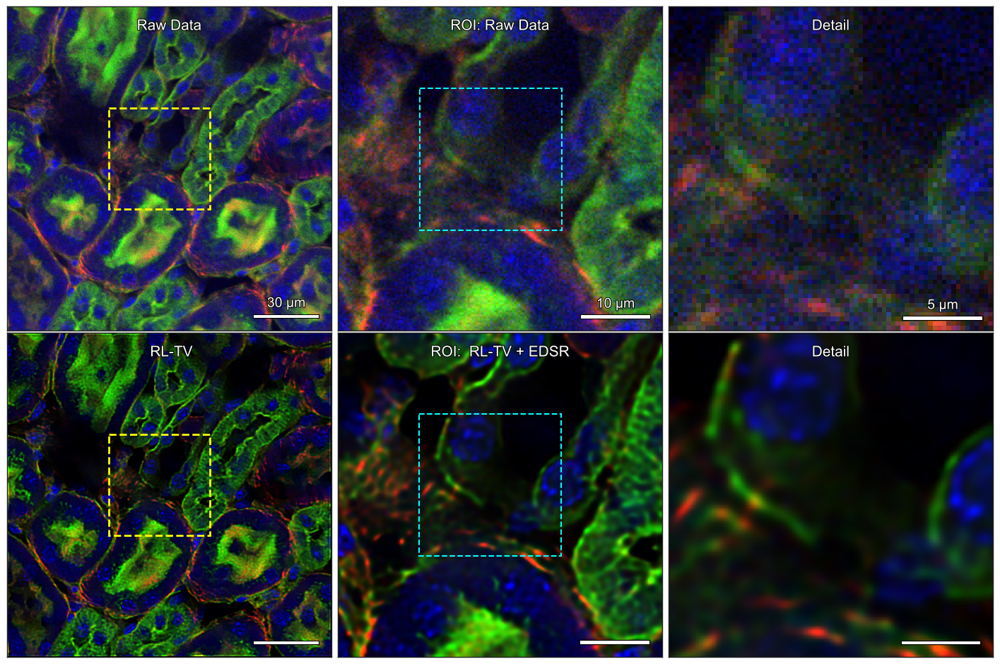

In [20]:
# =============================================================================
# PUBLICATION FIGURE — Full image → ROI zoom → ROI detail
# Layout:
#   Row 1: Raw full image  |  SR full image  (large, side by side)
#   Row 2: Raw ROI crop    |  SR ROI crop    |  Raw detail  |  SR detail
# Saved to /Users/francesco/Repositories /noise_images/IMM/
# =============================================================================
from pathlib import Path
import matplotlib.patches as patches
import matplotlib.patheffects as pe

SAVE_DIR = Path("/Users/francesco/Repositories /noise_images/IMM")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ── ROI and detail coordinates ────────────────────────────────────────────────
ZOOM_Y0, ZOOM_Y1 = 160, 320      # ROI in full image
ZOOM_X0, ZOOM_X1 = 160, 320

# Sub-crop inside the ROI (coordinates relative to the ROI itself)
# → targets a single nucleus or membrane region of interest
DET_Y0, DET_Y1 = 40, 110        # adjust to your structure of interest
DET_X0, DET_X1 = 40, 110

# ── Reconstruct SR full-image composite for display ───────────────────────────
# roi_sr is the 640×640 SR patch; for the full-image panel we use rgb_deconv
# (the closest full-frame equivalent to the SR quality)
img_full_raw = np.clip(rgb_raw,    0, 1)
img_full_sr  = np.clip(rgb_deconv, 0, 1)   # full frame — SR only computed on ROI

# ── Crops ─────────────────────────────────────────────────────────────────────
roi_raw_crop = np.clip(rgb_raw[ZOOM_Y0:ZOOM_Y1, ZOOM_X0:ZOOM_X1], 0, 1)
roi_sr_crop  = np.clip(roi_sr, 0, 1)          # already cropped + upscaled

# Detail inside ROI — from original ROI (not SR) for raw,
# from roi_sr (scaled coords) for SR
det_raw = roi_raw_crop[DET_Y0:DET_Y1, DET_X0:DET_X1]

# Scale detail coordinates to SR resolution (UPSCALE_FACTOR×)
F = UPSCALE_FACTOR
det_sr  = roi_sr_crop[DET_Y0*F:DET_Y1*F, DET_X0*F:DET_X1*F]

# ── Rectangle helper ──────────────────────────────────────────────────────────
def draw_rect(ax, x0, y0, x1, y1, color="yellow", lw=2, ls="--"):
    ax.add_patch(patches.Rectangle(
        (x0, y0), x1 - x0, y1 - y0,
        linewidth=lw, edgecolor=color, linestyle=ls, fill=False, zorder=5))

# =============================================================================
# FIGURE — Layout 2x3 (Cornici neutre, barre proporzionate identiche)
#   Row 1: Raw full (sx) | Raw ROI (centro) | Raw Det (dx)  <-- Con testo µm
#   Row 2: SR full  (sx) | SR ROI  (centro) | SR Det  (dx)  <-- Solo linea
# =============================================================================
import seaborn as sns
import matplotlib.patheffects as pe

# 1. Impostiamo Seaborn per una grafica pulita e sfondo bianco
sns.set_theme(style="white", rc={"axes.facecolor": "white", "figure.facecolor": "white"})

# 2. Figsize 18x12: aspect ratio 3:2 perfetto per 6 immagini
fig = plt.figure(figsize=(18, 12), facecolor='white')
gs  = fig.add_gridspec(
    2, 3,
    hspace=0.0,               # Righe completamente attaccate
    wspace=0.02,              # Leggera fessura tra le colonne
)

# ── Funzione per i titoli in sovrimpressione ─────────────────────────────────
def add_inset_title(ax, text):
    ax.text(0.5, 0.96, text, transform=ax.transAxes,
            color="white", fontsize=15, ha="center", va="top", weight="normal",
            path_effects=[pe.withStroke(linewidth=1.5, foreground="black")],
            zorder=10)

# ── Colonna Sx: Full images ──────────────────────────────────────────────────
ax_raw_full = fig.add_subplot(gs[0, 0])
ax_sr_full  = fig.add_subplot(gs[1, 0])

ax_raw_full.imshow(img_full_raw)
ax_raw_full.set_xticks([]); ax_raw_full.set_yticks([])
add_inset_title(ax_raw_full, "Raw Data")
draw_rect(ax_raw_full, ZOOM_X0, ZOOM_Y0, ZOOM_X1, ZOOM_Y1, color="yellow", lw=2)

ax_sr_full.imshow(img_full_sr)
ax_sr_full.set_xticks([]); ax_sr_full.set_yticks([])
add_inset_title(ax_sr_full, " RL-TV")
draw_rect(ax_sr_full, ZOOM_X0, ZOOM_Y0, ZOOM_X1, ZOOM_Y1, color="yellow", lw=2)

# ── Colonne Dx (Riga 1): ROI zoom (Raw e SR affiancate) ──────────────────────
ax_roi_raw = fig.add_subplot(gs[0, 1])
ax_roi_sr  = fig.add_subplot(gs[1, 1])

ax_roi_raw.imshow(roi_raw_crop)
ax_roi_raw.set_xticks([]); ax_roi_raw.set_yticks([])
add_inset_title(ax_roi_raw, "ROI: Raw Data")
draw_rect(ax_roi_raw, DET_X0, DET_Y0, DET_X1, DET_Y1, color="cyan", lw=1.5)

ax_roi_sr.imshow(roi_sr_crop)
ax_roi_sr.set_xticks([]); ax_roi_sr.set_yticks([])
add_inset_title(ax_roi_sr, "ROI:  RL-TV + EDSR")
draw_rect(ax_roi_sr, DET_X0 * F, DET_Y0 * F, DET_X1 * F, DET_Y1 * F, color="cyan", lw=1.5)

# ── Colonne Dx (Riga 2): Detail zoom (Raw e SR affiancate) ───────────────────
ax_det_raw = fig.add_subplot(gs[0, 2])
ax_det_sr  = fig.add_subplot(gs[1, 2])

ax_det_raw.imshow(det_raw, interpolation="nearest")
ax_det_raw.set_xticks([]); ax_det_raw.set_yticks([])
add_inset_title(ax_det_raw, "Detail")

ax_det_sr.imshow(det_sr, interpolation="nearest")
ax_det_sr.set_xticks([]); ax_det_sr.set_yticks([])
add_inset_title(ax_det_sr, "Detail")

# ── Bordi delle immagini (Spines) uniformi ───────────────────────────────────
# Rimossi gli aloni gialli e ciano. Ora tutte hanno un bordo nero/grigio pulito.
all_axes = [ax_raw_full, ax_sr_full, ax_roi_raw, ax_roi_sr, ax_det_raw, ax_det_sr]
for ax in all_axes:
    for spine in ax.spines.values():
        spine.set_edgecolor("#222222") # Grigio molto scuro / Nero
        spine.set_linewidth(1.0)       # Spessore sottile e pulito

# ── Shared scale bar su TUTTI i pannelli ─────────────────────────────────────
UM_FULL   = 30
UM_ROI    = 10
UM_DETAIL = 5

axes_to_scale = [
    (ax_raw_full, False, UM_FULL,   True),  
    (ax_sr_full,  False, UM_FULL,   False), 
    (ax_roi_raw,  False, UM_ROI,    True),  
    (ax_roi_sr,   True,  UM_ROI,    False), 
    (ax_det_raw,  False, UM_DETAIL, True),  
    (ax_det_sr,   True,  UM_DETAIL, False)  
]

for ax, is_upscaled, um_val, show_text in axes_to_scale:
    img_h, img_w = ax.images[0].get_array().shape[:2]
    
    sb_px = um_val * SCALE_PX_PER_UM * (F if is_upscaled else 1)
    
    mg = img_w * 0.04  # Margine (4% della larghezza)
    
    # FIX: Ancorando l'altezza della barra esattamente all'1% dei pixel dell'asse.
    # Poiché tutti gli assi vengono stampati con la stessa altezza fisica sulla 
    # figura matplotlib, l'1% corrisponderà sempre all'identico spessore visivo!
    bar_height = img_h * 0.010 
    
    rect = patches.Rectangle(
        (img_w - mg - sb_px, img_h - mg - bar_height), 
        sb_px, bar_height,
        facecolor="white", edgecolor="none", zorder=6
    )
    rect.set_path_effects([pe.withStroke(linewidth=1.5, foreground="black")])
    ax.add_patch(rect)
    
    # Testo (solo riga in alto)
    if show_text:
        # Anche il padding dev'essere una % fissa dell'immagine per non allontanarsi troppo nei dettagli
        text_padding = img_h * 0.015
        
        ax.text(img_w - mg - (sb_px / 2),
                img_h - mg - bar_height - text_padding, 
                f"{um_val} µm",
                color="white", fontsize=14, ha="center", va="bottom", weight="normal",
                path_effects=[pe.withStroke(linewidth=1.5, foreground="black")],
                zorder=7)

# ── Save ─────────────────────────────────────────────────────────────────────

out_png  = SAVE_DIR / "MERGING.png"

plt.savefig(out_png, bbox_inches="tight", facecolor="white", dpi=300)
plt.show()
plt.close("all")


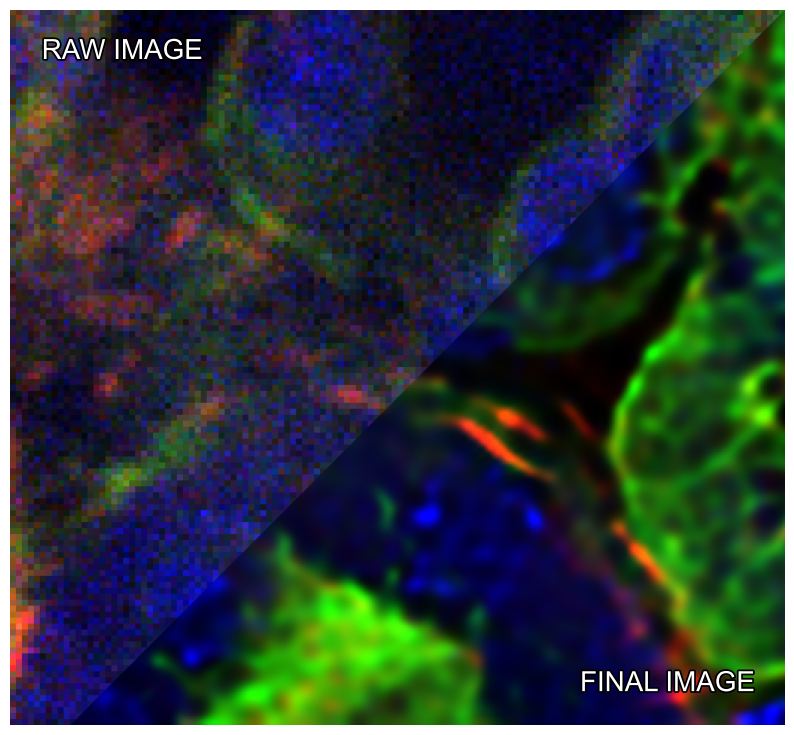

Salvato Split View in:
  /Users/francesco/Repositories /noise_images/IMM/diagonal.png


In [21]:
# =============================================================================
# DIAGONAL SPLIT VIEW: Allineamento Assoluto + Inquadratura spostata in giù
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from pathlib import Path

SAVE_DIR = Path("/Users/francesco/Repositories /noise_images/IMM")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Impostazioni Inquadratura (Quadrata)
SIZE = 130
# HO AGGIUNTO 15 PIXEL QUI: da 15 passiamo a 30 per spostare l'inquadratura verso il basso
SPLIT_Y0 = 40
SPLIT_X0 = 15

# 2. Upscale dell'INTERA ROI raw prima di tagliare (Garantisce l'allineamento perfetto)
raw_upscaled_full = np.repeat(np.repeat(roi_raw_crop, F, axis=0), F, axis=1)

# --- CORREZIONE SHIFT DELLA RETE NEURALE ---
# Se noti ancora che i filamenti non combaciano, cambia questi valori (es. 1, -1)
SHIFT_Y = 0  
SHIFT_X = 0  

# 3. Coordinate sulla griglia ad alta risoluzione (moltiplicate per F)
Y_start = SPLIT_Y0 * F
Y_end   = (SPLIT_Y0 + SIZE) * F
X_start = SPLIT_X0 * F
X_end   = (SPLIT_X0 + SIZE) * F

# 4. Estrazione Simultanea
split_raw_upscaled = raw_upscaled_full[Y_start:Y_end, X_start:X_end]

split_sr = roi_sr_crop[Y_start + SHIFT_Y : Y_end + SHIFT_Y, 
                       X_start + SHIFT_X : X_end + SHIFT_X]

H_sr, W_sr = split_sr.shape[:2]

# 5. Maschera diagonale perfetta a 45 gradi
y, x = np.indices((H_sr, W_sr))
mask = (x + y) < W_sr 
mask = mask[..., np.newaxis]

# 6. Unione chirurgica
split_image = np.where(mask, split_raw_upscaled, split_sr)

# 7. Visualizzazione
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(split_image)
ax.axis("off")

# 8. Etichette (Eleganti, font piccolo=24, ombra sottile)
text_effects = [pe.withStroke(linewidth=2.5, foreground="black")]

ax.text(W_sr * 0.04, H_sr * 0.04, "RAW IMAGE", color="white", fontsize=20, 
        fontweight="normal", ha="left", va="top", path_effects=text_effects, zorder=1)

ax.text(W_sr * 0.96, H_sr * 0.96, "FINAL IMAGE", color="white", fontsize=20, 
        fontweight="normal", ha="right", va="bottom", path_effects=text_effects, zorder=1)

# 9. Salvataggio
out_split_png = SAVE_DIR / "diagonal.png"

plt.savefig(out_split_png, bbox_inches="tight", pad_inches=0, facecolor="black", dpi=600)

plt.show()
plt.close()

print(f"Salvato Split View in:\n  {out_split_png}")